In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# **Download Data**

In [ ]:
!gdown 1L1CDOKDRW1tSReHCEibHw_nS7Vwi_1IM
!gdown 1M-pMev1QbH4Hc2Y7NcvMSmP_xNePJAPv
!gdown 1HSKrHda-Jo2YgZkDltrfbaXQCoormyCN
!gdown 1w2b9EDjOBGTGxzBISKCT7KMTNgl87CFn
!gdown 1idOF4EvANNd2dBBCe3TkKW2pxibo2S2N
!gdown 1-6wXkicrOrbBnoO6kF8huJEVO5hrrXMk
!gdown 1AyFyBNk4IdkA_HhDuyDg3ZfiSD4XbMTG
!gdown 15T6Bq_VppISFO03NAGU8iGm1ZsTxtUl9
!gdown 1IS5duZ90QArgK6d1xFlKrK9zIov_koh6
!gdown 1vjgUiHowQQsUtd4-la5MeL_1-JmPnlNx
!gdown 1b1KFG4d9vhWuCbAT7-1ztgxndSIw8xXM

Downloading...
From: https://drive.google.com/uc?id=1L1CDOKDRW1tSReHCEibHw_nS7Vwi_1IM
To: /content/dino_test_embeddings.pth
100% 4.61M/4.61M [00:00<00:00, 127MB/s]
Downloading...
From: https://drive.google.com/uc?id=1M-pMev1QbH4Hc2Y7NcvMSmP_xNePJAPv
To: /content/dino_test_labels.pth
100% 25.2k/25.2k [00:00<00:00, 36.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1HSKrHda-Jo2YgZkDltrfbaXQCoormyCN
To: /content/dino_train_and_test_file_names.json
100% 795k/795k [00:00<00:00, 116MB/s]
Downloading...
From: https://drive.google.com/uc?id=1w2b9EDjOBGTGxzBISKCT7KMTNgl87CFn
To: /content/dino_train_embeddings.pth
100% 45.7M/45.7M [00:00<00:00, 70.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1idOF4EvANNd2dBBCe3TkKW2pxibo2S2N
To: /content/dino_train_labels.pth
100% 239k/239k [00:00<00:00, 85.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-6wXkicrOrbBnoO6kF8huJEVO5hrrXMk
To: /content/sup_test_embeddings.npy
100% 6.14M/6.14M [00:00<00:00, 112MB/s]
Downloading..

In [ ]:
import torch
import numpy as np
import json
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm
import csv

In [ ]:
# dino train stuffs
dino_train_embeddings = torch.load("./dino_train_embeddings.pth")
dino_train_labels = torch.load("./dino_train_labels.pth")
with open('dino_train_and_test_file_names.json') as f:
  dino_train_file_names = json.load(f)['train_file_names']

# dino test stuffs
dino_test_embeddings = torch.load("./dino_test_embeddings.pth")
dino_test_labels = torch.load("./dino_test_labels.pth")
with open('dino_train_and_test_file_names.json') as f:
  dino_test_file_names = json.load(f)['test_file_names']

# sup train stuffs
supervised_train_embeddings = np.load("./sup_train_embeddings.npy")
supervised_train_labels = np.load("./sup_train_labels.npy")
with open('sup_train_file_names.json') as f:
  supervised_train_file_names = json.load(f)['test_file_names']

# sup test stuffs
supervised_test_embeddings = np.load("./sup_test_embeddings.npy")
supervised_test_labels = np.load("./sup_test_labels.npy")
with open('sup_test_file_names.json') as f:
  supervised_test_file_names = json.load(f)['test_file_names']

In [ ]:
# dino train stuffs
dino_train_embeddings = np.asarray(dino_train_embeddings)
dino_train_labels = np.asarray(dino_train_labels)
dino_train_file_names = dino_train_file_names

# dino test stuffs
dino_test_embeddings = np.asarray(dino_test_embeddings)
dino_test_labels = np.asarray(dino_test_labels)
dino_test_file_names = dino_test_file_names

# supervised train stuffs
supervised_train_embeddings = np.asarray(supervised_train_embeddings)
supervised_train_labels = np.asarray(supervised_train_labels)
for i, name in enumerate(supervised_train_file_names):
  supervised_train_file_names[i] = (name.split("/")[-1])[2:]

# supervised test stuffs
supervised_test_embeddings = np.asarray(supervised_test_embeddings)
supervised_test_labels = np.asarray(supervised_test_labels)
for i, name in enumerate(supervised_test_file_names):
  supervised_test_file_names[i] = (name.split("/")[-1])[2:]

# **Use CSV File**

In [ ]:
!gdown 1wTFXe68GJeuCNgcNSuf99okoT_HhxO1P

Downloading...
From: https://drive.google.com/uc?id=1wTFXe68GJeuCNgcNSuf99okoT_HhxO1P
To: /content/csv_for_k_5.csv
100% 27.2M/27.2M [00:00<00:00, 126MB/s] 


# **Preparing Data**

In [ ]:
import torch
from PIL import Image
import os
import torchvision
import tarfile
from torchvision.datasets.utils import download_url
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as tt
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from torchvision.utils import make_grid
import matplotlib
import torchvision.transforms as T
import matplotlib.pyplot as plt
import random
import pandas as pd
%matplotlib inline
matplotlib.rcParams['figure.facecolor'] = '#ffffff'

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

In [ ]:
df = pd.read_csv("./csv_for_k_5.csv", header=None)

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        first_file_name = str(df.iloc[idx][0])
        first_file_index = dino_train_file_names.index(first_file_name)
        first_embedding = torch.tensor(dino_train_embeddings[first_file_index, :])
        first_embedding = first_embedding.reshape(1, 1, -1)

        second_file_name = str(df.iloc[idx][1])
        second_file_index = dino_train_file_names.index(second_file_name)
        second_embedding = torch.tensor(dino_train_embeddings[second_file_index, :])
        second_embedding = second_embedding.reshape(1, 1, -1)

        # Add [CLS] token before tensor1
        cls_token = torch.ones_like(first_embedding[:, :1, :])
        first_embedding_with_cls = torch.cat([cls_token, first_embedding], dim=1)

        # Add [SEP] token between tensor1 and tensor2
        sep_token = torch.ones_like(first_embedding[:, :1, :])
        cls_first_embedding_sep_second_embedding = torch.cat([first_embedding_with_cls, sep_token, second_embedding], dim=1)

        label = int(df.iloc[idx][2])

        return cls_first_embedding_sep_second_embedding.squeeze(), label

In [ ]:
dataset = CustomDataset(df)
val_size = int(len(dataset) * 0.1)
train_size = len(dataset) - val_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
len(train_ds), len(val_ds)

(535176, 59464)

In [ ]:
batch_size = 64

In [ ]:
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=batch_size * 2)

# **Model**

In [ ]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

class RerankerBase(nn.Module):
    def training_step(self, sequences, labels):
        out = self(sequences)
        loss = F.cross_entropy(out, labels)
        return loss

    def validation_step(self, sequences, labels):
        out = self(sequences)
        loss = F.cross_entropy(out, labels)
        acc = accuracy(out, labels)
        return {'val_loss': loss.detach(), 'val_acc': acc}

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss = torch.stack(batch_losses).mean()
        batch_accs = [x['val_acc'] for x in outputs]
        epoch_acc = torch.stack(batch_accs).mean()
        return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}

    def epoch_end(self, epoch, result):
        print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch, result['train_loss'], result['val_loss'], result['val_acc']))

In [ ]:
def get_default_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def to_device(data, device):
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        return len(self.dl)

In [ ]:
device = get_default_device()
device

device(type='cuda')

In [ ]:
class Reranker(RerankerBase):
    def __init__(self, input_dim, num_layers, num_heads, classifier_output_dim):
        super(Reranker, self).__init__()

        self.encoder_layer = nn.TransformerEncoderLayer(d_model=input_dim, nhead=num_heads)
        self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
        self.classifier_head = nn.Linear(input_dim, classifier_output_dim)

    def forward(self, x):
        transformer_output = self.transformer_encoder(x)
        cls_embedding = transformer_output[:, 0, :]
        classifier_output = torch.sigmoid(self.classifier_head(cls_embedding))
        return classifier_output

# **evaluate and train**

In [ ]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [model.validation_step(batch[0], batch[1]) for batch in tqdm(val_loader)]
    return model.validation_epoch_end(outputs)

def fit(epochs, lr, model, train_loader, val_loader, opt_func=torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), lr)
    for epoch in range(epochs):
        # Training Phase
        model.train()
        train_losses = []
        for batch in tqdm(train_loader):
            loss = model.training_step(batch[0], batch[1])
            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        # Validation phase
        result = evaluate(model, val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        model.epoch_end(epoch, result)
        history.append(result)
    return history

# **let's train**

In [ ]:
model = Reranker(
    input_dim=384,
    num_layers=4,
    num_heads=8,
    classifier_output_dim=2
)
train_dl = DeviceDataLoader(train_dl, device)
val_dl = DeviceDataLoader(val_dl, device)
to_device(model, device)
epochs = 5
max_lr = 0.001
opt_func = torch.optim.Adam

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


In [ ]:
pytorch_total_params = sum(p.numel() for p in model.parameters())
pytorch_total_params

10841730

In [ ]:
history = fit(epochs, max_lr, model, train_dl, val_dl, opt_func)

100%|██████████| 465/465 [01:01<00:00,  7.58it/s]


Epoch [0], train_loss: 0.6932, val_loss: 0.6931, val_acc: 0.4990


100%|██████████| 465/465 [01:02<00:00,  7.41it/s]


Epoch [1], train_loss: 0.6931, val_loss: 0.6931, val_acc: 0.4990


100%|██████████| 465/465 [01:01<00:00,  7.55it/s]


Epoch [2], train_loss: 0.6931, val_loss: 0.6931, val_acc: 0.4990


100%|██████████| 465/465 [01:01<00:00,  7.58it/s]


Epoch [3], train_loss: 0.6931, val_loss: 0.6931, val_acc: 0.4990


100%|██████████| 465/465 [01:01<00:00,  7.51it/s]


Epoch [4], train_loss: 0.6931, val_loss: 0.6931, val_acc: 0.4990


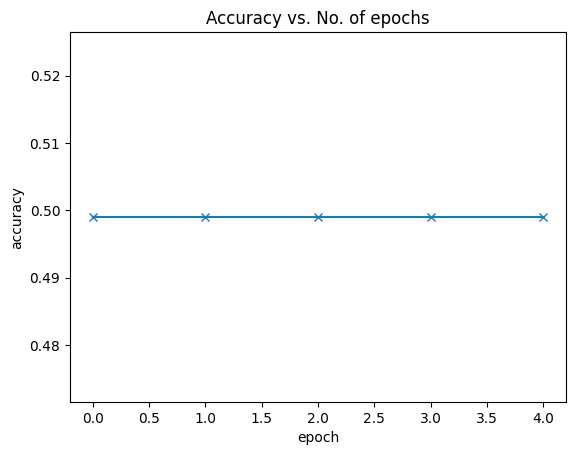

In [ ]:
def plot_accuracies(history):
    accuracies = [x['val_acc'] for x in history]
    plt.plot(accuracies, '-x')
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title('Accuracy vs. No. of epochs')

plot_accuracies(history)

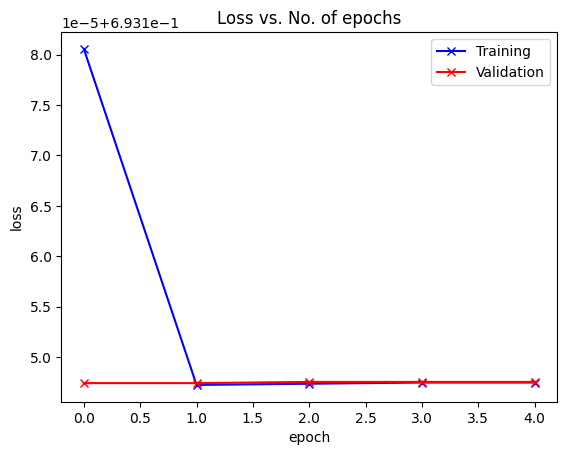

In [ ]:
def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx')
    plt.plot(val_losses, '-rx')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss vs. No. of epochs')

plot_losses(history)